# Приведение временных рядов к стационарности

**Задача.** Для шести классических временных рядов проверить стационарность расширенным тестом Дики–Фуллера (ADF) и подобрать преобразования (логарифмирование, первая и сезонная разности), после которых ряд становится стационарным.

**Данные.** Шесть рядов из Time Series Data Library (каталог `../data/`): рождаемость девочек в Калифорнии (дневной), авиапассажиры, среднемесячная температура, вооружённые ограбления в Бостоне, продажи компании X (месячные), закрытия индекса Dow Jones (недельный).

**План.**
1. Для каждого ряда — ADF-тест и график исходного ряда.
2. Подбор преобразования: log для стабилизации дисперсии, `diff(1)` для тренда, `diff(12)` для сезонности.
3. Повторный ADF-тест и график преобразованного ряда; уровень значимости 0.05.

Приведение временного ряда к стационарности - это фундаментальный шаг в классическом анализе временных рядов. Он необходим для того, чтобы закономерности, которые модель выучит на исторических данных, оставались справедливыми и для будущего.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import numpy as np
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

DATA_DIR = '../data/'

In [2]:
# Функция для ADF-теста (H0: у ряда есть единичный корень, т.е. ряд нестационарен)
def check_stationarity(series, title):
    stat, pvalue = adfuller(series.dropna(), autolag='AIC')[:2]
    print(f"--- {title} ---")
    print(f"ADF Statistic: {stat:.4f}")
    print(f"p-value: {pvalue:.4f}")
    print("Стационарен" if pvalue < 0.05 else "Нестационарен")
    print("-" * 30)

## 1. Рождаемость девочек в Калифорнии (1959, дневные данные)

--- Исходный ряд ---
ADF Statistic: -4.8083
p-value: 0.0001
Стационарен
------------------------------


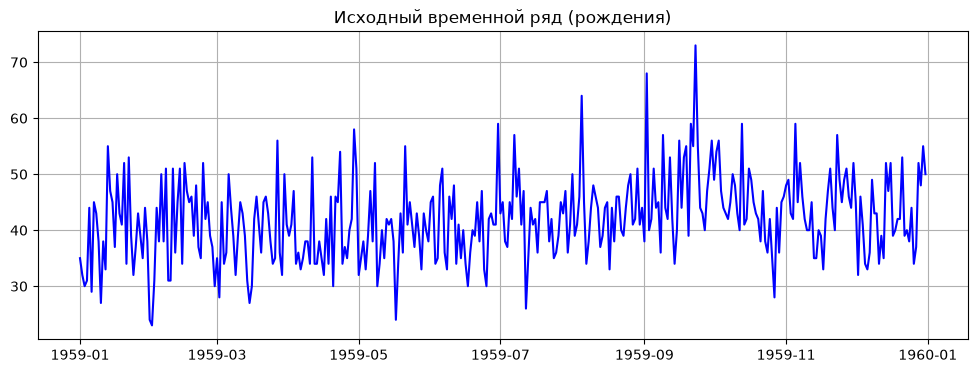

--- После первой разности (diff) ---
ADF Statistic: -12.6252
p-value: 0.0000
Стационарен
------------------------------


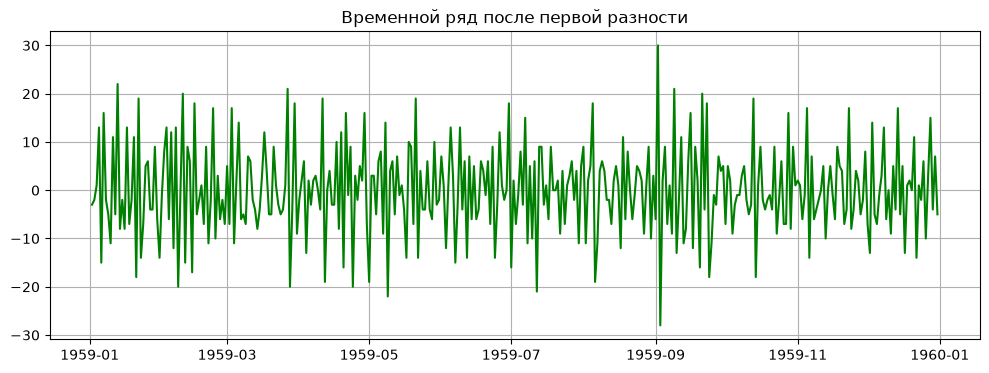

In [3]:
df = pd.read_csv(DATA_DIR + 'daily-total-female-births-in-cal.csv', parse_dates=['Date'], index_col='Date')

# Анализ исходного ряда
check_stationarity(df['Count'], "Исходный ряд")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count'], color='blue')
plt.title("Исходный временной ряд (рождения)")
plt.grid(True)
plt.show()

# Преобразование: первая разность
df['Count_diff'] = df['Count'].diff()

# Анализ преобразованного ряда
check_stationarity(df['Count_diff'], "После первой разности (diff)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count_diff'], color='green')
plt.title("Временной ряд после первой разности")
plt.grid(True)
plt.show()

Ежедневное количество рождений девочек в Калифорнии за 1959 год.

- Исходный ряд: ADF Statistic = -4.8083, p-value = 0.0001 → формально уже стационарен (гипотеза о единичном корне отвергается). Однако в дневных данных такого типа часто присутствуют недельная сезонность и колебания дисперсии, которые могут мешать моделям (например, ARIMA).
- Для надёжности можно взять первую разность: ADF Statistic = -12.6252, p-value < 0.0001 — ряд стационарен с большим запасом. Строго говоря, для уже стационарного ряда это преобразование избыточно (риск передифференцирования), его стоит применять только если этого требует модель.

## 2. Авиапассажиры (1949–1960, месячные данные)

--- Исходный ряд ---
ADF Statistic: 0.8154
p-value: 0.9919
Нестационарен
------------------------------


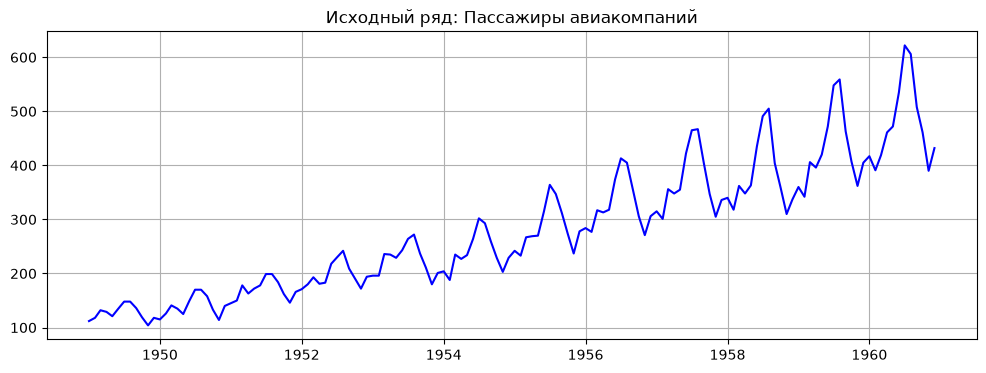

--- Log + 1-я разность ---
ADF Statistic: -2.7171
p-value: 0.0711
Нестационарен
------------------------------


--- Log + 1-я разность + Сезонная разность (lag=12) ---
ADF Statistic: -4.4433
p-value: 0.0002
Стационарен
------------------------------


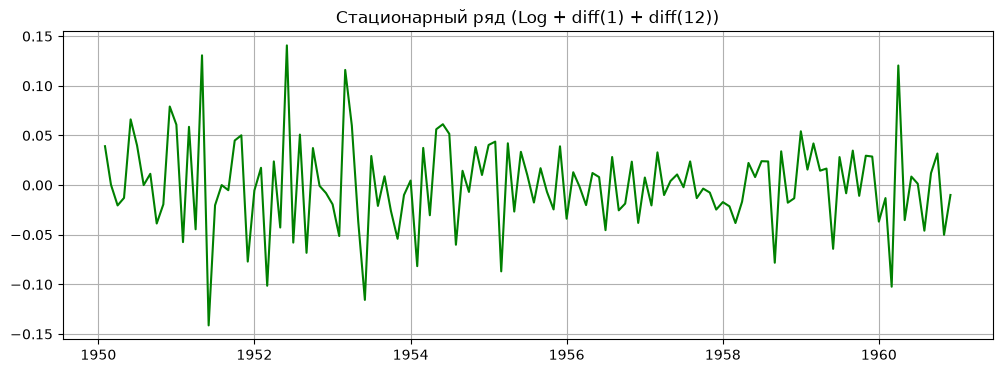

In [4]:
df = pd.read_csv(DATA_DIR + 'international-airline-passengers.csv')
df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
df.set_index('Month', inplace=True)

# Анализ исходного ряда
check_stationarity(df['Count'], "Исходный ряд")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count'], color='blue')
plt.title("Исходный ряд: Пассажиры авиакомпаний")
plt.grid(True)
plt.show()

# Преобразования для достижения стационарности
df['Count_log'] = np.log(df['Count'])                  # Стабилизация дисперсии
df['Count_log_diff1'] = df['Count_log'].diff()         # Удаление тренда
df['Count_log_diff12'] = df['Count_log_diff1'].diff(12) # Удаление сезонности (лаг 12 месяцев)

# Анализ преобразованного ряда
check_stationarity(df['Count_log_diff1'], "Log + 1-я разность")
check_stationarity(df['Count_log_diff12'], "Log + 1-я разность + Сезонная разность (lag=12)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count_log_diff12'], color='green')
plt.title("Стационарный ряд (Log + diff(1) + diff(12))")
plt.grid(True)
plt.show()

Классический ряд с трендом и мультипликативной сезонностью (амплитуда колебаний растёт со временем).

- Исходный ряд: ADF Statistic = 0.8154, p-value = 0.9919 → нестационарен (тренд и сезонность).
- Log + первая разность: p-value = 0.0711 → всё ещё нестационарен (тренд убран, сезонность осталась).
- Log + первая разность + сезонная разность (лаг 12): ADF Statistic = -4.4433, p-value = 0.0002 → стационарен.

## 3. Среднемесячная температура (1920–1939)

--- Исходный ряд (температура) ---
ADF Statistic: -3.2555
p-value: 0.0170
Стационарен
------------------------------


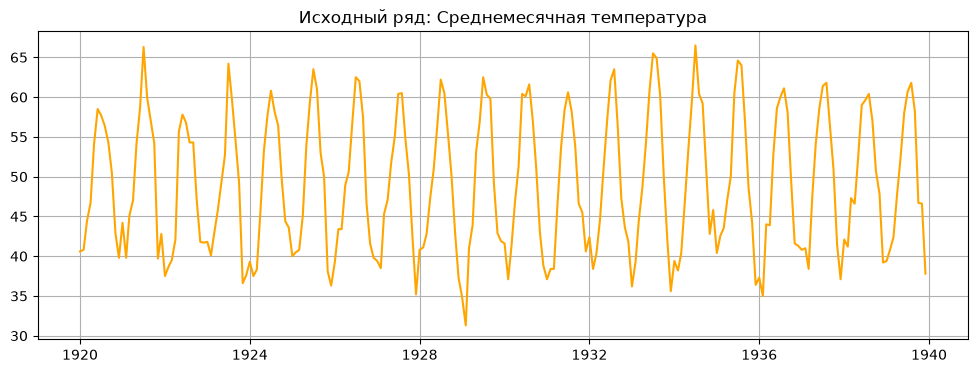

In [5]:
# Загрузка данных
df = pd.read_csv(DATA_DIR + 'mean-monthly-air-temperature-deg.csv')
df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
df.set_index('Month', inplace=True)

# Анализ исходного ряда
check_stationarity(df['Deg'], "Исходный ряд (температура)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Deg'], color='orange')
plt.title("Исходный ряд: Среднемесячная температура")
plt.grid(True)
plt.show()

In [6]:
# Дополнительная проверка: сезонная разность убирает годовой цикл
check_stationarity(df['Deg'].diff(12), "Сезонная разность (lag=12)")

--- Сезонная разность (lag=12) ---
ADF Statistic: -6.0725
p-value: 0.0000
Стационарен
------------------------------


Среднемесячная температура, 1920–1939. У ряда выраженная годовая сезонность (период 12 месяцев), но нет долгосрочного тренда — температура колеблется вокруг одного уровня год за годом.

- Исходный ряд: ADF Statistic = -3.2555, p-value = 0.0170 → по ADF стационарен без преобразований (тест проверяет наличие единичного корня, а устойчивый сезонный цикл его не создаёт).
- Если модели нужен ряд без сезонного цикла, достаточно сезонной разности: ADF Statistic = -6.0725, p-value < 0.0001.

## 4. Вооружённые ограбления в Бостоне (1966–1975)

--- Исходный ряд (ограбления) ---
ADF Statistic: 1.0011
p-value: 0.9943
Нестационарен
------------------------------


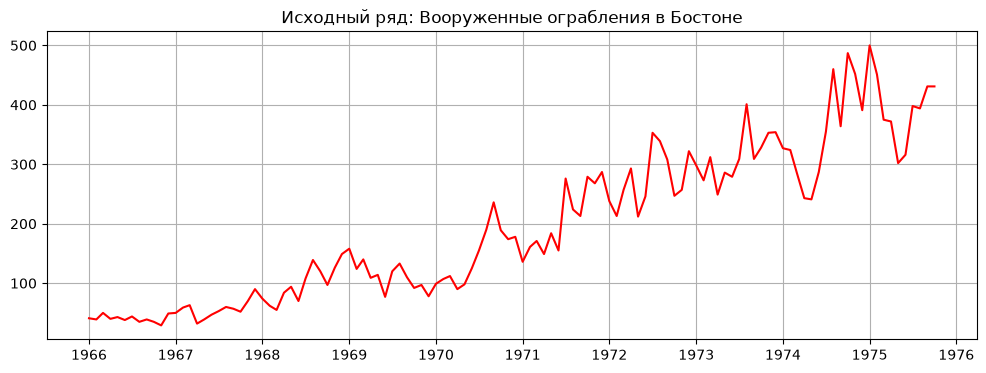

--- Log + 1-я разность ---
ADF Statistic: -7.6018
p-value: 0.0000
Стационарен
------------------------------


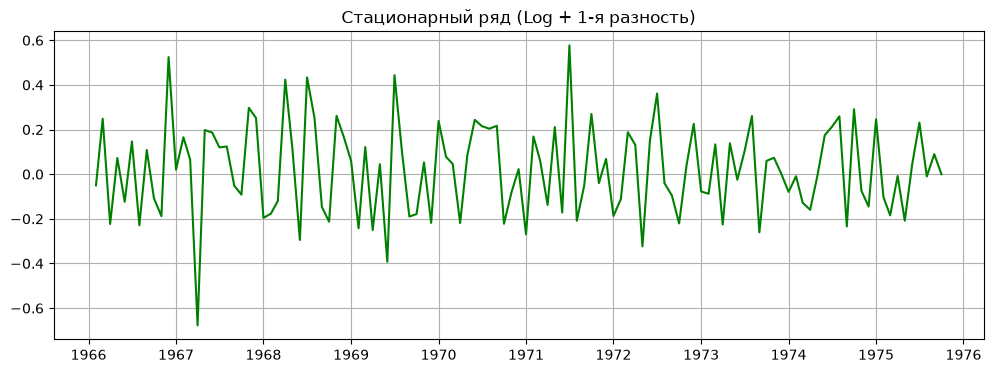

In [7]:
# Загрузка данных
df = pd.read_csv(DATA_DIR + 'monthly-boston-armed-robberies-j.csv')
df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
df.set_index('Month', inplace=True)

# Анализ исходного ряда
check_stationarity(df['Count'], "Исходный ряд (ограбления)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count'], color='red')
plt.title("Исходный ряд: Вооруженные ограбления в Бостоне")
plt.grid(True)
plt.show()

# Преобразования для достижения стационарности
df['Count_log'] = np.log(df['Count'])          # Стабилизация дисперсии
df['Count_log_diff1'] = df['Count_log'].diff() # Удаление сильного тренда

# Анализ преобразованного ряда
check_stationarity(df['Count_log_diff1'], "Log + 1-я разность")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count_log_diff1'], color='green')
plt.title("Стационарный ряд (Log + 1-я разность)")
plt.grid(True)
plt.show()

In [8]:
# Для сравнения: log + сезонная разность (lag=12) вместо первой разности
check_stationarity(df['Count_log'].diff(12), "Log + сезонная разность (lag=12)")

--- Log + сезонная разность (lag=12) ---
ADF Statistic: -2.6932
p-value: 0.0752
Нестационарен
------------------------------


Ежемесячные вооружённые ограбления в Бостоне (1966–1975).

- Исходный ряд: ADF Statistic = 1.0011, p-value = 0.9943 → нестационарен (сильный восходящий тренд: примерно с 40 до 430 ограблений в месяц).
- Log + первая разность: ADF Statistic = -7.6018, p-value < 0.0001 → стационарен.
- Log + сезонная разность (лаг 12) вместо первой: ADF Statistic = -2.6932, p-value = 0.0752 → нестационарен.

Вывод: для этого ряда достаточно логарифмирования (стабилизация растущей дисперсии) и первой разности. Основная проблема ряда — мощный тренд, а не сезонность, поэтому сезонная разность здесь не помогает.

## 5. Продажи компании X (1965–1971)

--- Исходный ряд (продажи) ---
ADF Statistic: 0.6547
p-value: 0.9889
Нестационарен
------------------------------


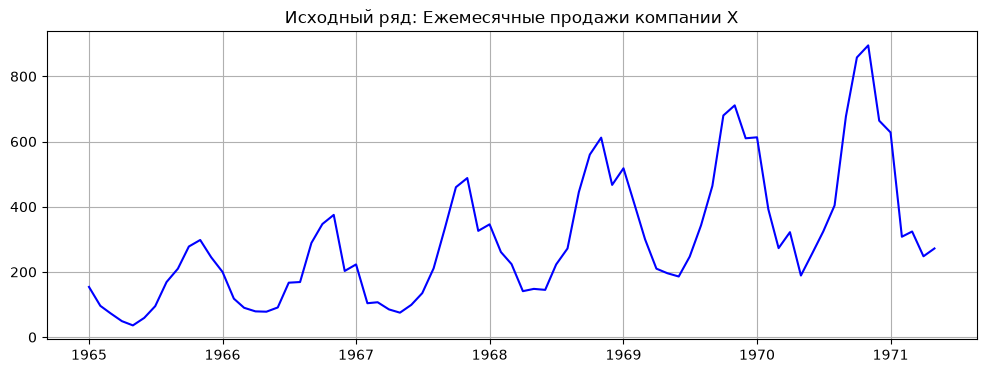

--- Log + 1-я разность ---
ADF Statistic: -3.1356
p-value: 0.0240
Стационарен
------------------------------


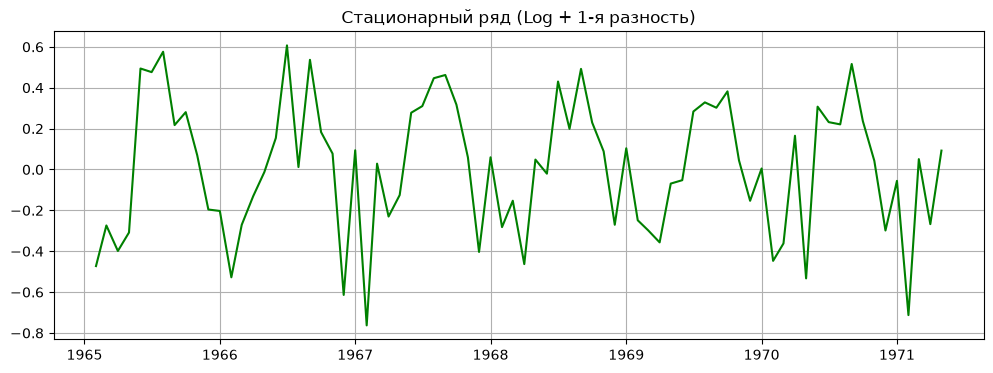

In [9]:
# Загрузка данных
df = pd.read_csv(DATA_DIR + 'monthly-sales-of-company-x-jan-6.csv')
df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
df.set_index('Month', inplace=True)

# Анализ исходного ряда
check_stationarity(df['Count'], "Исходный ряд (продажи)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count'], color='blue')
plt.title("Исходный ряд: Ежемесячные продажи компании X")
plt.grid(True)
plt.show()

# Преобразования для достижения стационарности
df['Count_log'] = np.log(df['Count'])          # Стабилизация дисперсии
df['Count_log_diff1'] = df['Count_log'].diff() # Удаление тренда

# Анализ преобразованного ряда
check_stationarity(df['Count_log_diff1'], "Log + 1-я разность")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Count_log_diff1'], color='green')
plt.title("Стационарный ряд (Log + 1-я разность)")
plt.grid(True)
plt.show()

In [10]:
# Проверка: нужна ли дополнительно сезонная разность
check_stationarity(df['Count_log_diff1'].diff(12), "Log + 1-я разность + сезонная разность (lag=12)")

--- Log + 1-я разность + сезонная разность (lag=12) ---
ADF Statistic: -2.3160
p-value: 0.1668
Нестационарен
------------------------------


Ежемесячные продажи компании X (январь 1965 — май 1971).

- Исходный ряд: ADF Statistic = 0.6547, p-value = 0.9889 → нестационарен (восходящий тренд и растущая амплитуда сезонных колебаний).
- Log + первая разность: ADF Statistic = -3.1356, p-value = 0.0240 → стационарен.
- Log + первая разность + сезонная разность (лаг 12): ADF Statistic = -2.3160, p-value = 0.1668 → нестационарен.

Вывод: для этого ряда достаточно логарифмирования и первой разности. Добавление сезонной разности ухудшает результат теста — признак передифференцирования; кроме того, ряд короткий (около 6 лет), и сезонная разность отнимает ещё 12 наблюдений.

## 6. Недельные закрытия Dow Jones (1971–1974)

--- Исходный ряд (Dow Jones) ---
ADF Statistic: -1.3146
p-value: 0.6225
Нестационарен
------------------------------


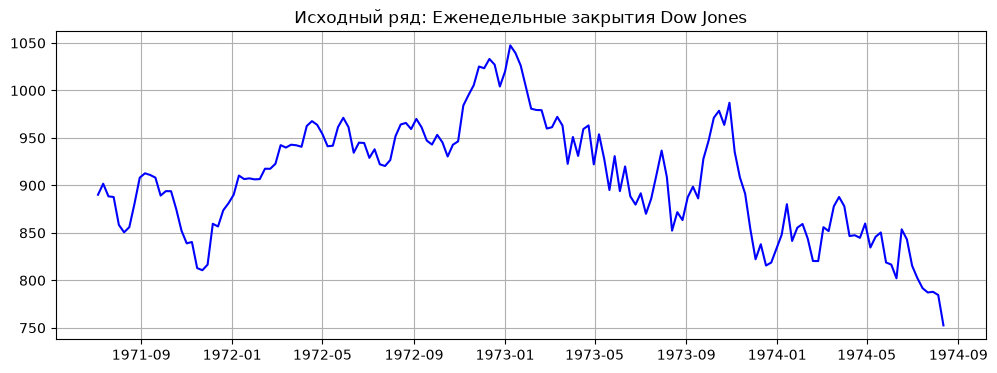

--- Log + 1-я разность (доходность) ---
ADF Statistic: -12.9958
p-value: 0.0000
Стационарен
------------------------------


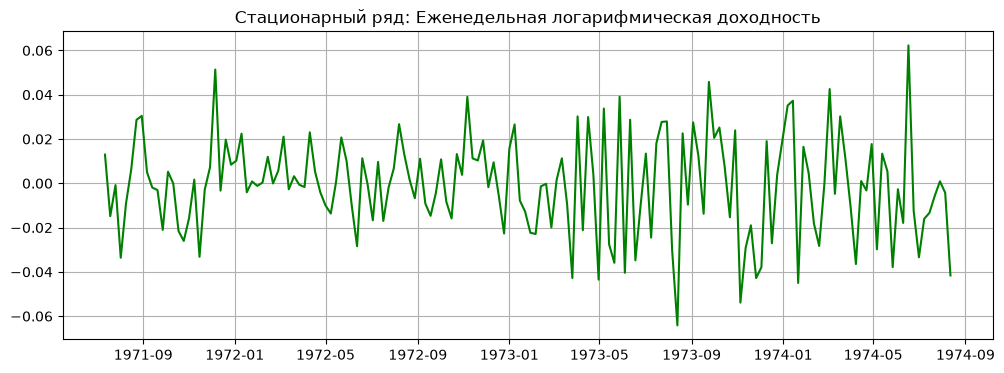

In [11]:
# Загрузка данных
df = pd.read_csv(DATA_DIR + 'weekly-closings-of-the-dowjones-.csv')
# Преобразуем строку вида "1971-W27" в корректную дату (понедельник этой недели)
df['Week'] = pd.to_datetime(df['Week'] + '-1', format='%Y-W%W-%w')
df.set_index('Week', inplace=True)

# Анализ исходного ряда
check_stationarity(df['Close'], "Исходный ряд (Dow Jones)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Close'], color='blue')
plt.title("Исходный ряд: Еженедельные закрытия Dow Jones")
plt.grid(True)
plt.show()

# Преобразования для достижения стационарности
# Логарифмическая первая разность (наиболее предпочтительна для финансовых данных, так как это "доходность")
df['Close_log_diff1'] = np.log(df['Close']).diff()

# Анализ преобразованного ряда
check_stationarity(df['Close_log_diff1'], "Log + 1-я разность (доходность)")

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Close_log_diff1'], color='green')
plt.title("Стационарный ряд: Еженедельная логарифмическая доходность")
plt.grid(True)
plt.show()

In [12]:
# Для сравнения: первая разность без логарифмирования
check_stationarity(df['Close'].diff(), "1-я разность (без log)")

--- 1-я разность (без log) ---
ADF Statistic: -13.0252
p-value: 0.0000
Стационарен
------------------------------


Недельные закрытия индекса Dow Jones (1971–1974).

- Исходный ряд: ADF Statistic = -1.3146, p-value = 0.6225 → нестационарен; типичное для финансовых рядов поведение, близкое к случайному блужданию.
- Первая разность: ADF Statistic = -13.0252, p-value < 0.0001 → стационарен.
- Log + первая разность (недельная логарифмическая доходность): ADF Statistic = -12.9958, p-value < 0.0001 → стационарен.

Вывод: для цен и индексов стандартный приём — переход к первым разностям или логарифмическим доходностям; сезонная разность не нужна.

## Выводы

| Ряд | Исходный ряд, p-value ADF | Преобразование | p-value после |
|---|---|---|---|
| Рождаемость (дневной) | 0.0001 | не требуется (diff даёт -12.63) | < 0.0001 |
| Авиапассажиры | 0.9919 | log + diff(1) + diff(12) | 0.0002 |
| Температура | 0.0170 | не требуется (при необходимости diff(12)) | < 0.0001 |
| Ограбления в Бостоне | 0.9943 | log + diff(1) | < 0.0001 |
| Продажи компании X | 0.9889 | log + diff(1) | 0.0240 |
| Dow Jones (недельный) | 0.6225 | log + diff(1) | < 0.0001 |

- Логарифм стабилизирует дисперсию у рядов с растущей амплитудой (пассажиры, продажи, ограбления).
- Первая разность убирает тренд; сезонная разность нужна только там, где сезонность сильная и устойчивая (пассажиры). Для продаж и ограблений она ухудшает результат теста.
- ADF проверяет только наличие единичного корня; формальная стационарность по ADF (температура, рождаемость) не означает отсутствия сезонности, поэтому решение о преобразовании стоит принимать вместе с графиком и ACF.